<a href="https://colab.research.google.com/github/hodamalak/data-science-python-projects/blob/main/Deep%20Learning%20Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install tensorflow scikeras

In [ ]:
!pip install scikit-learn==1.2.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 29.2 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scikeras 0.13.0 requires scikit-learn>=1.4.2, but you have scikit-learn 1.2.2 which is incompatible.
imbalanced-learn 0.13.0 requires scikit-learn<2,>=1.3.2, but you have scikit-learn 1.2.2 which is incompatible.
mlxtend 0.23.4 requires scikit-learn>=1.3.1, but you have scikit-learn 1.2.2 which is incompatible.


Mounted at /content/drive
Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6532 - loss: 0.6214 - val_accuracy: 0.6748 - val_loss: 0.6168 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7078 - loss: 0.5589 - val_accuracy: 0.7073 - val_loss: 0.5711 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6895 - loss: 0.5595 - val_accuracy: 0.6911 - val_loss: 0.5386 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7161 - loss: 0.5158 - val_accuracy: 0.7073 - val_loss: 0.5176 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7380 - loss: 0.5331 - val_accuracy: 0.7561 - val_loss: 0.4905 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7529 - loss: 0.4884 - val_accuracy: 0.7642 - val_loss: 0.4775 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0

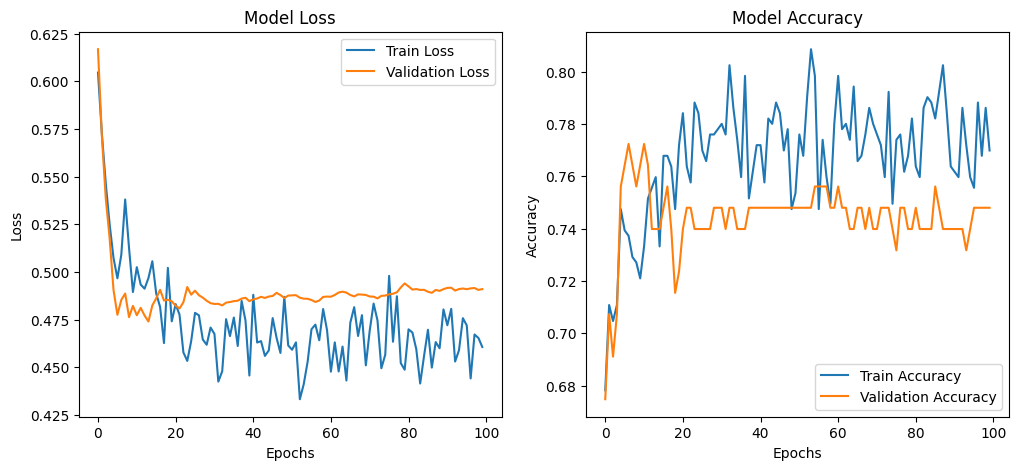

10-Fold Cross-Validation Accuracy: 76.06% (±4.21%)


In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import keras as k
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from scikeras.wrappers import KerasClassifier  # scikeras wrapper for cross-validation
from keras.models import Sequential
from keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

from google.colab import drive
drive.mount('/content/drive')

# Load dataset
filename = "/content/drive/MyDrive/Colab Notebooks/pima_diabetes (1).csv"
col_names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
df = pd.read_csv(filename, names=col_names)

# Split dataset into features (X) and target variable (y)
X = df.iloc[:, :-1].values  # Features
y = df.iloc[:, -1].values   # Target (1 = Diabetes, 0 = No Diabetes)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the feature data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define Redesigned MLP Model
def build_mlp():
    model = Sequential()

    # First Hidden Layer
    model.add(Dense(32, input_dim=8))
    model.add(BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU(alpha=0.1))

    # Second Hidden Layer
    model.add(Dense(16))
    model.add(BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU(alpha=0.1))

    # Third Hidden Layer
    model.add(Dense(8, activation='relu'))

    # Dropout Layer to reduce overfitting
    model.add(Dropout(0.2))

    # Output Layer
    model.add(Dense(1, activation='sigmoid'))

    # Compile the Model
    optimizer = Adam(learning_rate=0.001)
    model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model

# Create Model
model = build_mlp()

# Implement Learning Rate Reduction on Plateau
lr_reduction = ReduceLROnPlateau(monitor='val_loss', patience=5, verbose=1, factor=0.5, min_lr=0.0001)

# Train the Model
history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, batch_size=10, callbacks=[lr_reduction], verbose=1)

# Evaluate Model on Test Set
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Plot Training & Validation Loss and Accuracy
def plot_training_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Loss Plot
    ax[0].plot(history.history['loss'], label='Train Loss')
    ax[0].plot(history.history['val_loss'], label='Validation Loss')
    ax[0].set_title('Model Loss')
    ax[0].set_xlabel('Epochs')
    ax[0].set_ylabel('Loss')
    ax[0].legend()

    # Accuracy Plot
    ax[1].plot(history.history['accuracy'], label='Train Accuracy')
    ax[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax[1].set_title('Model Accuracy')
    ax[1].set_xlabel('Epochs')
    ax[1].set_ylabel('Accuracy')
    ax[1].legend()

    plt.show()

# Display Training Progress
plot_training_history(history)

# Define 10-Fold Cross-Validation Model
def build_cv_model():
    return build_mlp()

cv_model = KerasClassifier(model=build_cv_model, epochs=200, batch_size=5, verbose=0)

# Define 10-Fold Cross-Validation
kfold = KFold(n_splits=10, shuffle=True, random_state=7)

# Perform Cross-Validation
results = cross_val_score(cv_model, X_train, y_train, cv=kfold)

# Print Cross-Validation Results
print(f"10-Fold Cross-Validation Accuracy: {results.mean() * 100:.2f}% (±{results.std() * 100:.2f}%)")
